# Analyse des résultats de la chaîne A

Ce notebook analyse `experiments/baselines.csv`, que produit `python src/run_baselines.py` :
**une ligne par patch de la partition de test**, avec le `theta = (u, v, w, z, alpha)`
estimé par Quegan sur la covariance du patch, le crosstalk initial et résiduel, et la
cohérence HV/VH avant et après correction.

Trois rappels pour lire les résultats (README, « Validation : trois niveaux de preuve ») :

- le **résiduel** est jugé par l'estimateur lui-même : il ne prouve rien et ne compare pas
  des méthodes ;
- la **réciprocité** est un juge indépendant, mais peu sensible (environ 2·10⁻³ pour une
  erreur de −30 dB) et aveugle à `alpha` ;
- il n'y a **pas de vérité terrain** sur ces patchs : ce notebook décrit le comportement de
  Quegan sur la pile, il ne dit pas si ses `theta` sont justes.

Plan : 1. contrôle d'intégrité — 2. synthèse — 3. distributions — 4. fiabilité selon la
cohérence HV/VH — 5. par date — 6. dépendance en distance — 7. cohérence en azimut —
8. plan complexe — 9. cartes — 10. corrélations — 11. patchs extrêmes — 12. à retenir.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap, Normalize
from scipy.stats import spearmanr

# Le notebook se lance depuis notebooks/ comme depuis la racine du dépôt.
RACINE = Path.cwd() if (Path.cwd() / "experiments").is_dir() else Path.cwd().parent
CSV = RACINE / "experiments" / "baselines.csv"

# Encres et surfaces ; cinq teintes catégorielles, une par date dans l'ordre chronologique ;
# une rampe bleue pour les grandeurs continues, et sa version ordinale à trois pas pour les
# classes de cohérence. Palette validée (séparation daltonisme, contraste) : trois teintes
# passent sous 3:1 sur la surface, d'où une table à côté de chaque graphique.
SURFACE, GRILLE, AXE = "#fcfcfb", "#e1e0d9", "#c3c2b7"
ENCRE, ENCRE_2, MUET = "#0b0b0b", "#52514e", "#898781"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
RAMPE = LinearSegmentedColormap.from_list(
    "bleus", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
)
BLEU, BLEU_CLAIR = "#2a78d6", "#cde2fb"
COULEURS_CLASSES = ["#86b6ef", "#2a78d6", "#104281"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXE, "axes.linewidth": 0.8, "axes.labelcolor": ENCRE_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": ENCRE, "axes.prop_cycle": cycler(color=SERIES),
    "xtick.color": MUET, "ytick.color": MUET, "xtick.labelcolor": ENCRE_2, "ytick.labelcolor": ENCRE_2,
    "text.color": ENCRE, "font.family": "sans-serif", "font.size": 9,
    "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
})
pd.options.display.float_format = "{:.3f}".format

## 1. Chargement et contrôle d'intégrité

La date se lit dans la clé torchcvnn de l'acquisition (`..._160211_L_090_04_BC`) : les
acquisitions n'y sont pas rangées dans l'ordre chronologique. Les paramètres complexes sont
reconstruits à partir de leurs parties réelle et imaginaire.

In [2]:
brut = pd.read_csv(CSV)
brut["date"] = pd.to_datetime(brut["acquisition"].str.extract(r"_(\d{6})_L_")[0], format="%y%m%d")

MESURES = ["initial_db", "residual_db", "reduction_db", "alpha_abs", "reciprocity_before", "reciprocity_after"]
positions = np.r_[brut["ligne"], brut["colonne"]]
par_emplacement = brut.groupby(["ligne", "colonne"]).size()

pd.Series({
    "lignes": len(brut),
    "statut ok": int((brut["status"] == "ok").sum()),
    "statut ill_conditioned": int((brut["status"] != "ok").sum()),
    "valeurs non finies (lignes ok)": int((~np.isfinite(brut.loc[brut["status"] == "ok", MESURES])).sum().sum()),
    "doublons de position": int(brut.duplicated(["acquisition", "ligne", "colonne"]).sum()),
    "emplacements au sol": len(par_emplacement),
    "dates par emplacement (min / max)": f"{par_emplacement.min()} / {par_emplacement.max()}",
    "pas de la grille (px)": int(np.gcd.reduce(positions[positions > 0])),
}, name="contrôle").to_frame()

,contrôle
lignes,73765
statut ok,73765
statut ill_conditioned,0
valeurs non finies (lignes ok),0
doublons de position,0
emplacements au sol,14753
dates par emplacement (min / max),5 / 5
pas de la grille (px),64


In [3]:
# Les lignes `ill_conditioned` n'ont pas de mesure : on ne garde que les patchs estimés.
d = brut[brut["status"] == "ok"].copy()

PARAMETRES = ["u", "v", "w", "z"]
for nom in PARAMETRES + ["alpha"]:
    d[nom] = d[f"{nom}_re"] + 1j * d[f"{nom}_im"]
for nom in PARAMETRES:
    d[f"{nom}_db"] = 20 * np.log10(np.abs(d[nom]))
d["alpha_phase_deg"] = np.degrees(np.angle(d["alpha"]))

DATES = sorted(d["date"].unique())
NOM_DATE = {date: f"{pd.Timestamp(date):%d/%m/%Y}" for date in DATES}
COULEUR_DATE = dict(zip(DATES, SERIES))
print(f"{len(d)} patchs estimés, {len(DATES)} dates :", ", ".join(NOM_DATE.values()))

73765 patchs estimés, 5 dates : 11/02/2016, 20/05/2016, 10/06/2016, 16/08/2016, 20/09/2016


## 2. Synthèse globale

La ligne « médiane » reproduit le tableau qu'affiche `run_baselines.py`. Les centiles 1 et 99
et les extrêmes montrent les queues de distribution, que la médiane cache.

In [4]:
synthese = d[MESURES].quantile([0.01, 0.25, 0.5, 0.75, 0.99]).T
synthese.columns = ["p1", "q1", "médiane", "q3", "p99"]
synthese["min"], synthese["max"] = d[MESURES].min(), d[MESURES].max()
synthese

,p1,q1,médiane,q3,p99,min,max
initial_db,-28.395,-22.682,-20.334,-17.721,-10.467,-33.127,-3.061
residual_db,-44.689,-33.604,-30.182,-26.947,-16.472,-62.053,2.536
reduction_db,1.422,7.627,9.701,12.207,23.580,-15.423,39.780
alpha_abs,0.196,1.007,1.180,1.224,3.262,0.001,454.675
reciprocity_before,0.065,0.546,0.767,0.891,0.973,0.001,0.996
reciprocity_after,0.065,0.560,0.788,0.905,0.977,0.002,0.990


## 3. Distributions

En haut à gauche, crosstalk initial et résiduel sur le même axe en dB. `|alpha|` est en
échelle logarithmique sur ses deux axes : presque tous les patchs tombent autour de 1,2, mais
ses valeurs aberrantes s'étendent sur six ordres de grandeur.

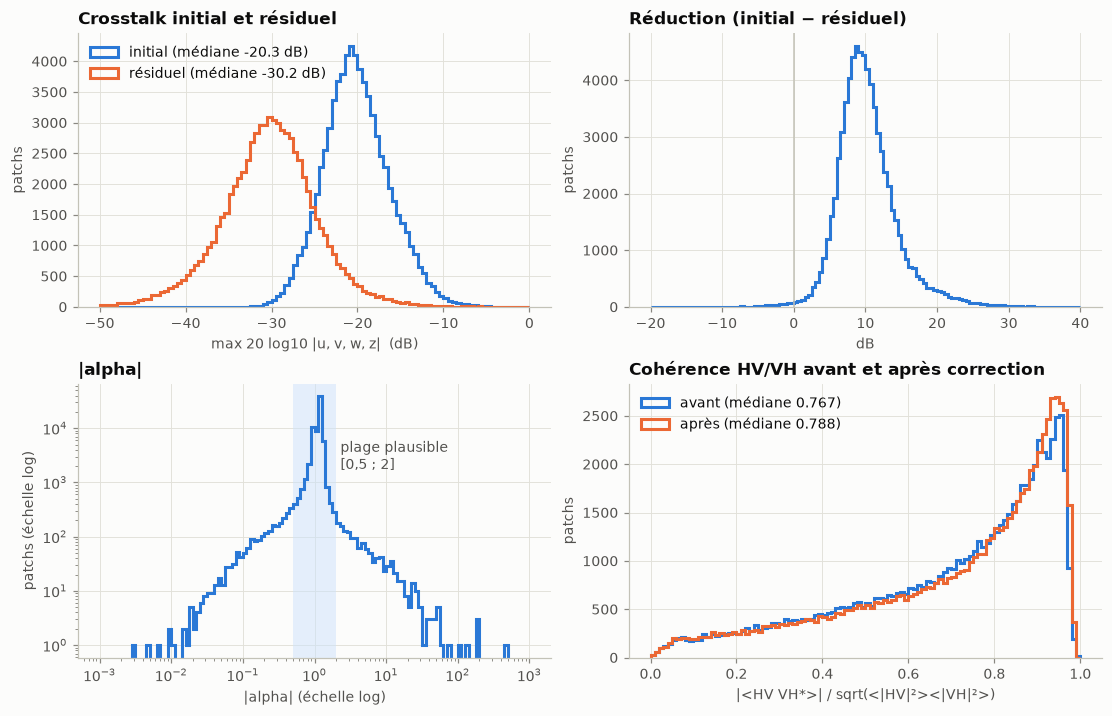

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), constrained_layout=True)

ax = axes[0, 0]
bornes = np.linspace(-50, 0, 101)
for colonne, nom, couleur in (("initial_db", "initial", SERIES[0]), ("residual_db", "résiduel", SERIES[1])):
    ax.hist(d[colonne], bins=bornes, histtype="step", color=couleur, linewidth=2, label=f"{nom} (médiane {d[colonne].median():.1f} dB)")
ax.set(title="Crosstalk initial et résiduel", xlabel="max 20 log10 |u, v, w, z|  (dB)", ylabel="patchs")
ax.legend(loc="upper left")

ax = axes[0, 1]
ax.hist(d["reduction_db"], bins=np.linspace(-20, 40, 121), histtype="step", color=SERIES[0], linewidth=2)
ax.axvline(0, color=AXE, linewidth=1)
ax.set(title="Réduction (initial − résiduel)", xlabel="dB", ylabel="patchs")

ax = axes[1, 0]
ax.hist(d["alpha_abs"], bins=np.logspace(-3, 3, 121), histtype="step", color=SERIES[0], linewidth=2)
ax.set(xscale="log", yscale="log")
ax.axvspan(0.5, 2, color=BLEU_CLAIR, alpha=0.5, linewidth=0)
ax.text(2.3, 3e3, "plage plausible\n[0,5 ; 2]", color=ENCRE_2, va="center")
ax.set(title="|alpha|", xlabel="|alpha| (échelle log)", ylabel="patchs (échelle log)")

ax = axes[1, 1]
bornes = np.linspace(0, 1, 101)
for colonne, nom, couleur in (("reciprocity_before", "avant", SERIES[0]), ("reciprocity_after", "après", SERIES[1])):
    ax.hist(d[colonne], bins=bornes, histtype="step", color=couleur, linewidth=2, label=f"{nom} (médiane {d[colonne].median():.3f})")
ax.set(title="Cohérence HV/VH avant et après correction", xlabel="|<HV VH*>| / sqrt(<|HV|²><|VH|²>)", ylabel="patchs")
ax.legend(loc="upper left")
plt.show()

Le résiduel suit le crosstalk initial, environ 10 dB en dessous : le nuage est parallèle à la
diagonale, et la réduction ne dépend pas du niveau de départ (voir les corrélations, §10).
C'est ce qu'on attend si le résiduel ré-estimé reflète surtout l'erreur propre de Quegan, qui
est **relative** — un biais de l'ordre de 30 % du crosstalk, soit −10 dB (README, « Le biais
propre de Quegan »). La réduction mesure alors la méthode, pas la correction. La densité est en
échelle logarithmique.

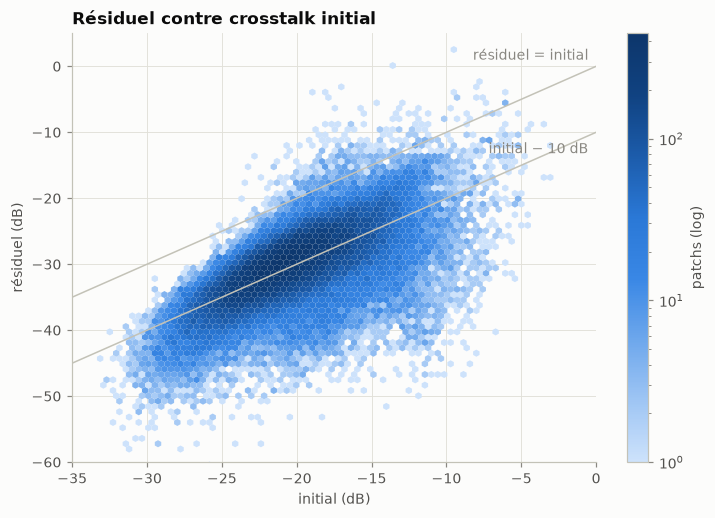

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 4.6), constrained_layout=True)
nuage = ax.hexbin(d["initial_db"], d["residual_db"], gridsize=70, cmap=RAMPE, bins="log", mincnt=1, linewidths=0)
ax.plot([-35, 0], [-35, 0], color=AXE, linewidth=1)
ax.plot([-35, 0], [-45, -10], color=AXE, linewidth=1)
ax.text(-0.5, 0.5, "résiduel = initial", color=MUET, ha="right", va="bottom")
ax.text(-0.5, -11.5, "initial − 10 dB", color=MUET, ha="right", va="top")
ax.set(title="Résiduel contre crosstalk initial", xlabel="initial (dB)", ylabel="résiduel (dB)",
       xlim=(-35, 0), ylim=(-60, 5))
fig.colorbar(nuage, ax=ax, label="patchs (log)")
plt.show()

## 4. Fiabilité selon la cohérence HV/VH

La cohérence HV/VH **avant** correction ne dépend d'aucun estimateur : elle caractérise le
patch. Elle sépare trois régimes :

- **≤ 0,3** — le signal croisé est noyé dans le bruit thermique : l'estimation de `alpha`, qui
  lit `<HV VH*>`, n'y voit que du bruit, et la réciprocité ne peut plus servir de juge ;
- **0,3 – 0,9** — le régime où Quegan se comporte comme attendu ;
- **> 0,9** — probablement des cibles qui violent la symétrie de réflexion (structures
  orientées) : Quegan y lit une corrélation propre à la scène comme du crosstalk.

Un patch est dit **aberrant** quand son crosstalk initial dépasse −15 dB, ou que `|alpha|` sort
de [0,5 ; 2] — loin des valeurs instrumentales (−20 dB, `|alpha|` ≈ 1,2).

In [7]:
d["aberrant"] = (d["initial_db"] > -15) | (d["alpha_abs"] < 0.5) | (d["alpha_abs"] > 2)
d["reciprocite_baisse"] = d["reciprocity_after"] < d["reciprocity_before"] - 1e-3

CLASSES = ["sombre (≤ 0,3)", "exploitable (0,3 – 0,9)", "très corrélé (> 0,9)"]
d["classe"] = pd.cut(d["reciprocity_before"], [0, 0.3, 0.9, 1.0], labels=CLASSES, include_lowest=True)
fiables = d[d["classe"] == CLASSES[1]]

fines = pd.cut(d["reciprocity_before"], [0, 0.3, 0.5, 0.7, 0.9, 1.0], include_lowest=True,
              labels=["≤ 0,3", "0,3 – 0,5", "0,5 – 0,7", "0,7 – 0,9", "> 0,9"])
groupes = d.groupby(fines, observed=True)
pd.DataFrame({
    "patchs": groupes.size(),
    "part": groupes.size() / len(d),
    "aberrants": groupes["aberrant"].mean(),
    "initial médian (dB)": groupes["initial_db"].median(),
    "résiduel médian (dB)": groupes["residual_db"].median(),
    "|alpha| médian": groupes["alpha_abs"].median(),
    "réciprocité qui baisse": groupes["reciprocite_baisse"].mean(),
}).rename_axis("cohérence HV/VH avant")

,patchs,part,aberrants,initial médian (dB),résiduel médian (dB),|alpha| médian,réciprocité qui baisse
cohérence HV/VH avant,,,,,,,
"≤ 0,3",6723,0.091,0.544,-19.569,-28.531,0.826,0.439
"0,3 – 0,5",9048,0.123,0.049,-20.602,-30.544,1.047,0.264
"0,5 – 0,7",14160,0.192,0.025,-21.161,-31.221,1.122,0.157
"0,7 – 0,9",27079,0.367,0.064,-21.207,-31.204,1.187,0.140
"> 0,9",16755,0.227,0.266,-17.275,-27.506,1.209,0.208


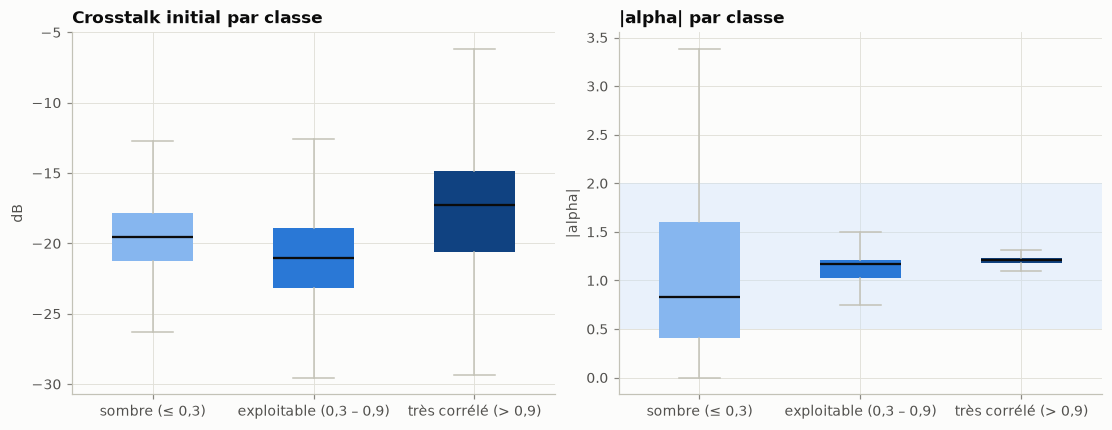

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
for ax, colonne, titre, unite in (
    (axes[0], "initial_db", "Crosstalk initial par classe", "dB"),
    (axes[1], "alpha_abs", "|alpha| par classe", "|alpha|"),
):
    boites = ax.boxplot(
        [d.loc[d["classe"] == classe, colonne] for classe in CLASSES],
        tick_labels=CLASSES, patch_artist=True, showfliers=False, widths=0.5,
        medianprops={"color": ENCRE, "linewidth": 1.5},
        whiskerprops={"color": AXE}, capprops={"color": AXE}, boxprops={"linewidth": 0},
    )
    for boite, couleur in zip(boites["boxes"], COULEURS_CLASSES):
        boite.set_facecolor(couleur)
    ax.set(title=titre, ylabel=unite)
axes[1].axhspan(0.5, 2, color=BLEU_CLAIR, alpha=0.4, linewidth=0)
plt.show()

## 5. Par date

Médianes par acquisition, sur tous les patchs puis sur la seule classe exploitable. Le 20 mai
ressort aussi comme la pire date chez Babu et al. (2022, figure 9).

In [9]:
def medianes(table):
    groupes = table.groupby("date")
    resultat = groupes[["initial_db", "residual_db", "alpha_abs", "reciprocity_before", "reciprocity_after"]].median()
    resultat.insert(0, "patchs", groupes.size())
    resultat["aberrants"] = groupes["aberrant"].mean()
    return resultat.rename(index=NOM_DATE)

pd.concat({"tous les patchs": medianes(d), "classe exploitable": medianes(fiables)})

patchs  initial_db  residual_db  alpha_abs  \
                   date                                                     
tous les patchs    11/02/2016   14753     -20.492      -30.603      1.199   
                   20/05/2016   14753     -18.609      -27.649      1.194   
                   10/06/2016   14753     -21.549      -31.946      1.207   
                   16/08/2016   14753     -20.640      -30.495      1.172   
                   20/09/2016   14753     -20.467      -30.679      0.976   
classe exploitable 11/02/2016   11032     -21.059      -31.375      1.189   
                   20/05/2016    9528     -19.415      -28.305      1.187   
                   10/06/2016   10556     -22.230      -32.906      1.194   
                   16/08/2016    9804     -21.319      -31.353      1.152   
                   20/09/2016    9367     -21.268      -31.684      0.980   

                               reciprocity_before  reciprocity_after  \
                   date                                                
tous les patchs    11/02/2016               0.779              0.802   
                   20/05/2016               0.797              0.820   
                   10/06/2016               0.752              0.770   
                   16/08/2016               0.770              0.787   
                   20/09/2016               0.729              0.748   
classe exploitable 11/02/2016               0.736              0.762   
                   20/05/2016               0.716              0.742   
                   10/06/2016               0.720              0.739   
                   16/08/2016               0.721              0.742   
                   20/09/2016               0.702              0.723   

                               aberrants  
                   date                   
tous les patchs    11/02/2016      0.100  
                   20/05/2016      0.209  
                   10/06/2016      0.102  
                   16/08/2016      0.149  
                   20/09/2016      0.161  
classe exploitable 11/02/2016      0.050  
                   20/05/2016      0.074  
                   10/06/2016      0.037  
                   16/08/2016      0.046  
                   20/09/2016      0.045

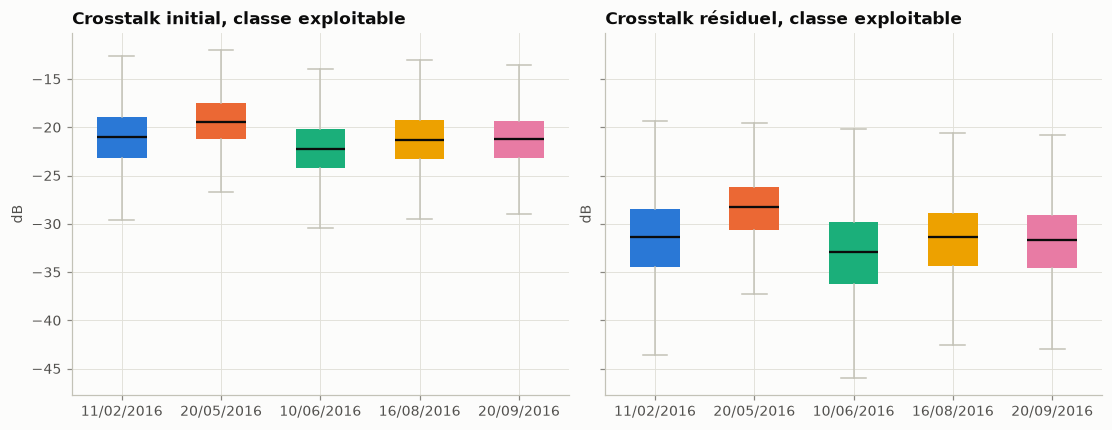

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True, sharey=True)
for ax, colonne, titre in ((axes[0], "initial_db", "Crosstalk initial"), (axes[1], "residual_db", "Crosstalk résiduel")):
    boites = ax.boxplot(
        [fiables.loc[fiables["date"] == date, colonne] for date in DATES],
        tick_labels=list(NOM_DATE.values()), patch_artist=True, showfliers=False, widths=0.5,
        medianprops={"color": ENCRE, "linewidth": 1.5},
        whiskerprops={"color": AXE}, capprops={"color": AXE}, boxprops={"linewidth": 0},
    )
    for boite, date in zip(boites["boxes"], DATES):
        boite.set_facecolor(COULEUR_DATE[date])
    ax.set(title=f"{titre}, classe exploitable", ylabel="dB")
plt.show()

## 6. Dépendance en distance

Le crosstalk instrumental ne dépend que de la distance (Fore et al., 2015, §V-B, figure 7).
Chaque point est la médiane des patchs d'une même colonne de la grille, classe exploitable,
toutes dates confondues ; la bande est l'écart interquartile. Les colonnes portant moins de
20 patchs sont ignorées.

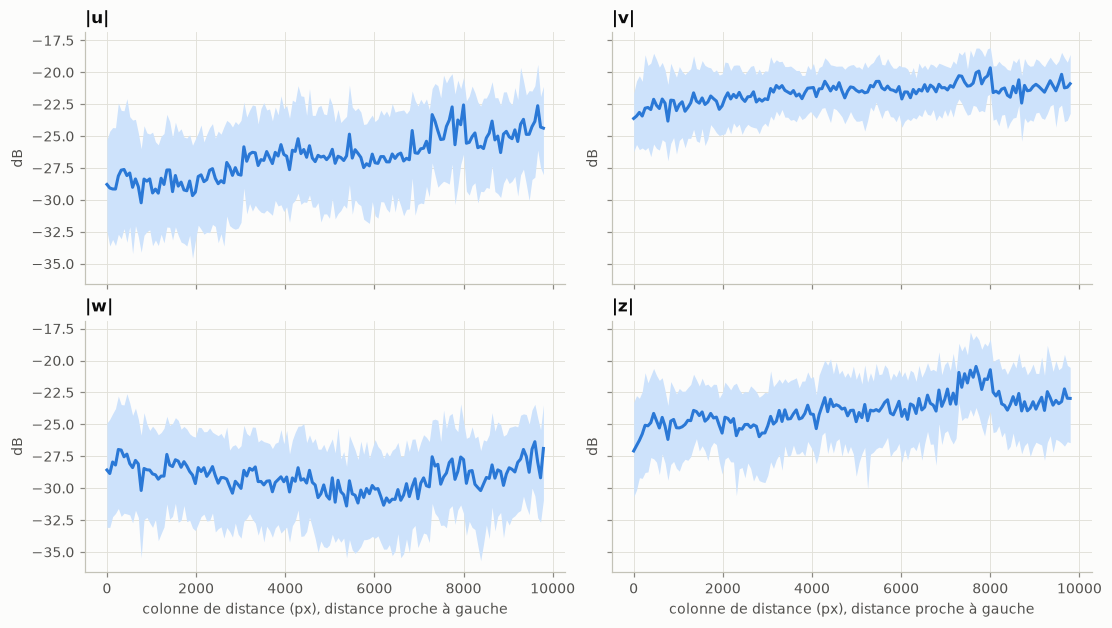

,médiane la plus basse (dB),médiane des colonnes (dB),médiane la plus haute (dB)
u,-30.223,-26.602,-22.553
v,-23.822,-21.466,-19.648
w,-31.395,-29.187,-26.354
z,-27.080,-23.923,-20.459


In [11]:
def profil(table, colonne):
    groupes = table.groupby("colonne")[colonne]
    resultat = pd.DataFrame({"q1": groupes.quantile(0.25), "médiane": groupes.median(), "q3": groupes.quantile(0.75),
                             "patchs": groupes.size()})
    return resultat[resultat["patchs"] >= 20]

fig, axes = plt.subplots(2, 2, figsize=(10, 5.6), constrained_layout=True, sharex=True, sharey=True)
for ax, nom in zip(axes.flat, PARAMETRES):
    p = profil(fiables, f"{nom}_db")
    ax.fill_between(p.index, p["q1"], p["q3"], color=BLEU_CLAIR, linewidth=0)
    ax.plot(p.index, p["médiane"], color=BLEU)
    ax.set(title=f"|{nom}|", ylabel="dB")
for ax in axes[1]:
    ax.set_xlabel("colonne de distance (px), distance proche à gauche")
plt.show()

pd.DataFrame({nom: profil(fiables, f"{nom}_db")["médiane"].describe()[["min", "50%", "max"]] for nom in PARAMETRES}).T.rename(
    columns={"min": "médiane la plus basse (dB)", "50%": "médiane des colonnes (dB)", "max": "médiane la plus haute (dB)"})

`alpha` par date : son module et sa phase, médianes par colonne de distance (classe
exploitable). Une date dont le profil s'écarte des autres signale un changement d'étalonnage
entre acquisitions, ou un artefact de l'estimation.

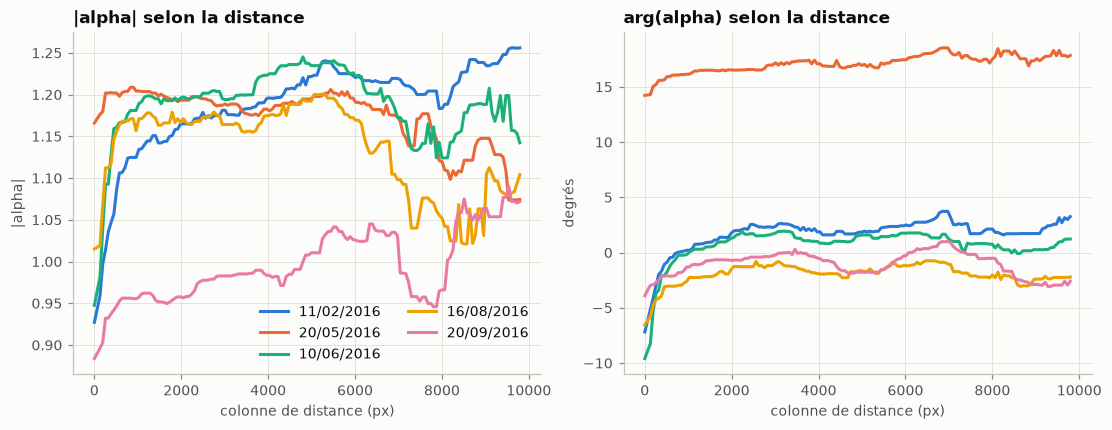

,alpha_abs,alpha_phase_deg
date,,
11/02/2016,1.189,1.757
20/05/2016,1.187,16.929
10/06/2016,1.194,0.778
16/08/2016,1.152,-1.896
20/09/2016,0.980,-0.964


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True, sharex=True)
for date in DATES:
    table = fiables[fiables["date"] == date]
    for ax, colonne in ((axes[0], "alpha_abs"), (axes[1], "alpha_phase_deg")):
        p = profil(table, colonne).rolling(5, center=True, min_periods=1).median()
        ax.plot(p.index, p["médiane"], color=COULEUR_DATE[date], label=NOM_DATE[date])
axes[0].set(title="|alpha| selon la distance", xlabel="colonne de distance (px)", ylabel="|alpha|")
axes[1].set(title="arg(alpha) selon la distance", xlabel="colonne de distance (px)", ylabel="degrés")
axes[0].legend(loc="best", ncols=2)
plt.show()

fiables.groupby("date")[["alpha_abs", "alpha_phase_deg"]].median().rename(index=NOM_DATE)

## 7. Cohérence en azimut

À date et colonne de distance fixées, le crosstalk instrumental est le même pour tous les
patchs : la dispersion des `theta` le long de l'azimut mesure donc le bruit d'estimation **plus
l'effet de scène**. Elle est exprimée comme l'écart médian au centre (médiane complexe),
rapporté au module du centre. C'est aussi le seul contrôle sur données réelles qui voie
`alpha`. Groupes d'au moins 20 patchs.

In [13]:
def dispersion_relative(valeurs):
    centre = np.median(valeurs.real) + 1j * np.median(valeurs.imag)
    return np.median(np.abs(valeurs - centre)) / np.abs(centre)

def dispersion(table):
    lignes = []
    for (date, colonne), groupe in table.groupby(["date", "colonne"]):
        if len(groupe) >= 20:
            lignes.append({"date": date, **{nom: dispersion_relative(groupe[nom].to_numpy()) for nom in PARAMETRES + ["alpha"]}})
    return pd.DataFrame(lignes).groupby("date").median().rename(index=NOM_DATE)

pd.concat({"tous les patchs": dispersion(d), "classe exploitable": dispersion(fiables)}).style.format("{:.0%}")

## 8. Les paramètres dans le plan complexe

Un crosstalk instrumental donne un nuage concentré, de phase stable ; un nuage diffus ou étiré
vers l'origine trahit le bruit ou la scène. Classe exploitable, toutes dates ; densité en échelle
logarithmique, croix à la médiane complexe.

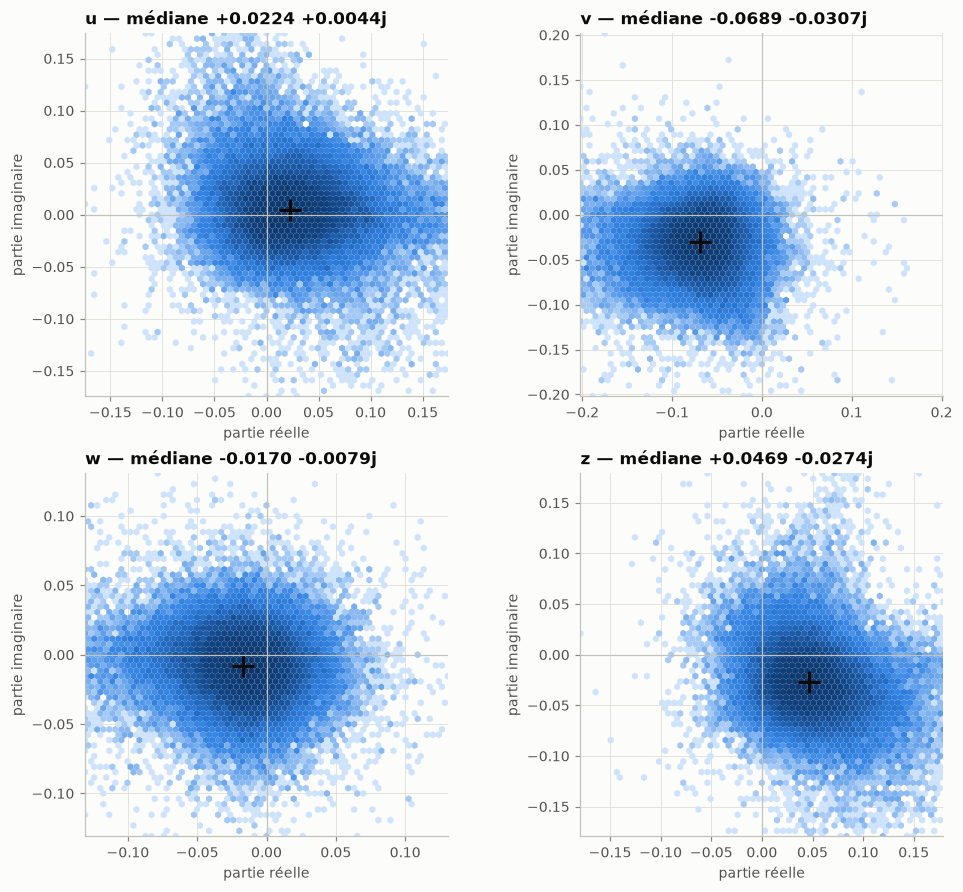

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8), constrained_layout=True)
for ax, nom in zip(axes.flat, PARAMETRES):
    valeurs = fiables[nom].to_numpy()
    limite = np.percentile(np.abs(valeurs), 98)
    ax.hexbin(valeurs.real, valeurs.imag, gridsize=60, cmap=RAMPE, bins="log", mincnt=1, linewidths=0,
              extent=(-limite, limite, -limite, limite))
    centre = np.median(valeurs.real) + 1j * np.median(valeurs.imag)
    ax.plot(centre.real, centre.imag, marker="+", markersize=14, markeredgewidth=2, color=ENCRE)
    ax.axhline(0, color=AXE, linewidth=0.8); ax.axvline(0, color=AXE, linewidth=0.8)
    ax.set(title=f"{nom} — médiane {centre.real:+.4f} {centre.imag:+.4f}j", xlabel="partie réelle", ylabel="partie imaginaire",
           xlim=(-limite, limite), ylim=(-limite, limite), aspect="equal")
plt.show()

## 9. Cartes

Position de chaque patch de test, distance en abscisse et azimut en ordonnée, comme la figure 8
de Fore et al. La partition de test ne retient qu'un emplacement sur dix : les cartes sont
clairsemées. En haut, le crosstalk initial (borné à [−30 ; −10] dB) ; en bas, les classes de
cohérence du 11 février.

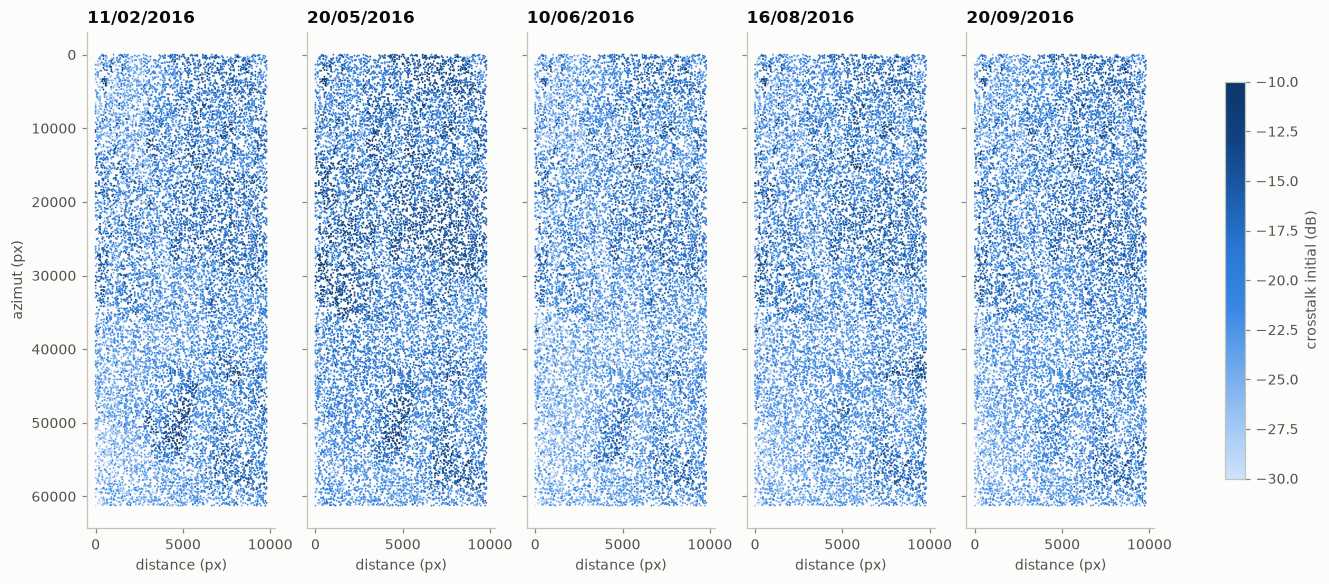

In [15]:
fig, axes = plt.subplots(1, len(DATES), figsize=(12, 5.2), constrained_layout=True, sharex=True, sharey=True)
echelle = Normalize(vmin=-30, vmax=-10)
for ax, date in zip(axes, DATES):
    table = d[d["date"] == date]
    points = ax.scatter(table["colonne"], table["ligne"], c=table["initial_db"], cmap=RAMPE, norm=echelle, s=1.5, linewidths=0)
    ax.set(title=NOM_DATE[date], xlabel="distance (px)")
    ax.grid(False)
axes[0].set_ylabel("azimut (px)")
axes[0].invert_yaxis()
fig.colorbar(points, ax=axes, label="crosstalk initial (dB)", shrink=0.8)
plt.show()

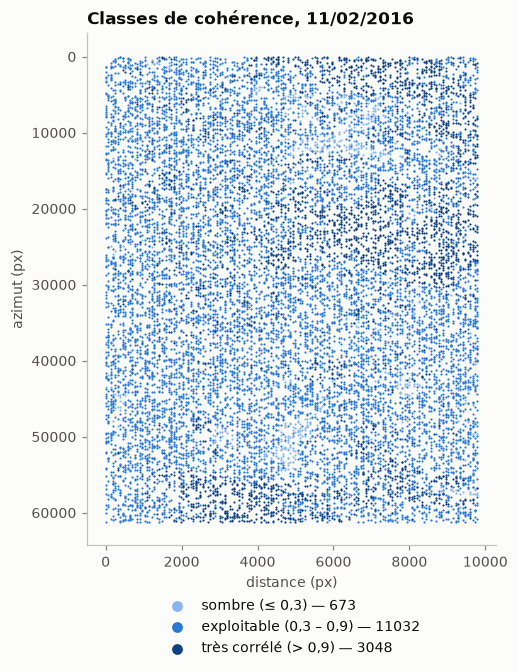

In [16]:
premiere = d[d["date"] == DATES[0]]
fig, ax = plt.subplots(figsize=(4.6, 6), constrained_layout=True)
for classe, couleur in zip(CLASSES, COULEURS_CLASSES):
    table = premiere[premiere["classe"] == classe]
    ax.scatter(table["colonne"], table["ligne"], color=couleur, s=2, linewidths=0, label=f"{classe} — {len(table)}")
ax.invert_yaxis()
ax.grid(False)
ax.set(title=f"Classes de cohérence, {NOM_DATE[DATES[0]]}", xlabel="distance (px)", ylabel="azimut (px)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), markerscale=5)
plt.show()

## 10. Corrélations

Corrélations de rang (Spearman) entre les mesures et la position du patch. La position en
distance (`colonne`) devrait corréler avec le crosstalk instrumental ; la position en azimut
(`ligne`) ne le devrait pas — une corrélation avec l'azimut est un effet de scène.

In [17]:
colonnes = ["initial_db", "residual_db", "reduction_db", "alpha_abs", "reciprocity_before", "reciprocity_after", "colonne", "ligne"]
pd.DataFrame(spearmanr(d[colonnes]).statistic, index=colonnes, columns=colonnes).style.format("{:+.2f}").background_gradient(
    cmap=LinearSegmentedColormap.from_list("divergente", ["#e34948", "#f0efec", "#2a78d6"]), vmin=-1, vmax=1)

,initial_db,residual_db,reduction_db,alpha_abs,reciprocity_before,reciprocity_after,colonne,ligne
initial_db,+1.00,+0.67,-0.01,+0.08,+0.19,+0.09,+0.29,-0.23
residual_db,+0.67,+1.00,-0.70,+0.11,+0.13,+0.10,+0.26,-0.01
reduction_db,-0.01,-0.70,+1.00,-0.05,+0.01,-0.03,-0.08,-0.20
alpha_abs,+0.08,+0.11,-0.05,+1.00,+0.27,+0.28,+0.12,-0.05
reciprocity_before,+0.19,+0.13,+0.01,+0.27,+1.00,+0.98,-0.05,-0.15
reciprocity_after,+0.09,+0.10,-0.03,+0.28,+0.98,+1.00,-0.10,-0.12
colonne,+0.29,+0.26,-0.08,+0.12,-0.05,-0.10,+1.00,+0.00
ligne,-0.23,-0.01,-0.20,-0.05,-0.15,-0.12,+0.00,+1.00


## 11. Patchs extrêmes

Les dix patchs au crosstalk initial le plus fort, et les dix au `|alpha|` le plus éloigné de 1.
Leurs positions permettent de les relire dans les `.slc`.

In [18]:
affichage = ["date", "ligne", "colonne", "initial_db", "residual_db", "alpha_abs", "reciprocity_before", "reciprocity_after"]
extremes = d.assign(date=d["date"].map(NOM_DATE), ecart_alpha=np.abs(np.log(d["alpha_abs"])))
display(extremes.nlargest(10, "initial_db")[affichage])
display(extremes.nlargest(10, "ecart_alpha")[affichage])

,date,ligne,colonne,initial_db,residual_db,alpha_abs,reciprocity_before,reciprocity_after
27203,20/05/2016,55680,8640,-3.061,-16.510,1.169,0.994,0.923
30208,20/05/2016,2368,8640,-3.167,-12.371,1.223,0.989,0.962
62723,20/05/2016,55808,8640,-3.362,-16.663,1.194,0.992,0.948
70643,20/05/2016,1920,8640,-3.509,-9.191,1.215,0.991,0.965
8623,20/05/2016,55360,7488,-4.431,-8.495,1.188,0.991,0.912
33493,20/05/2016,55104,8768,-4.629,-9.404,1.194,0.988,0.974
46978,20/05/2016,44032,2304,-4.639,-22.585,1.393,0.936,0.748
52778,20/05/2016,2112,6976,-4.641,-24.428,1.218,0.974,0.945
47323,20/05/2016,58048,8704,-4.788,-16.019,1.221,0.992,0.963
27213,20/05/2016,26752,9792,-4.839,-13.216,1.226,0.987,0.956


,date,ligne,colonne,initial_db,residual_db,alpha_abs,reciprocity_before,reciprocity_after
62314,16/08/2016,51776,9408,-17.976,-4.194,0.001,0.030,0.016
63292,20/09/2016,48256,5632,-18.996,-3.572,454.675,0.009,0.002
8700,10/06/2016,54272,4800,-9.682,2.536,0.003,0.006,0.030
24959,16/08/2016,48640,5312,-13.676,-0.183,0.005,0.059,0.020
10547,20/09/2016,32064,7808,-18.622,-9.832,185.693,0.011,0.006
66857,20/09/2016,49344,4992,-17.219,-2.877,184.800,0.005,0.005
9632,20/09/2016,35520,7936,-17.559,-9.004,180.538,0.015,0.006
16167,20/09/2016,13568,192,-23.203,-15.361,0.007,0.161,0.011
27967,20/09/2016,45248,9792,-17.412,-6.020,137.076,0.045,0.042
33512,20/09/2016,41600,8064,-18.173,-16.893,105.163,0.059,0.020


## 12. À retenir

Valeurs du lancement en patchs de 64 px (73 765 patchs de test, `seed: 38`). Elles changent si
`run_baselines.py` est relancé avec une autre configuration.

- **Intégrité.** 73 765 patchs, aucun échec, aucune valeur non finie, 14 753 emplacements
  × 5 dates, grille de 64 px.
- **Le chiffre résumé.** Crosstalk initial médian −20,3 dB, résiduel −30,2 dB.
- **La réduction d'environ 10 dB ne mesure pas la qualité de la correction.** Elle ne dépend
  pas du niveau initial (Spearman −0,01), et le résiduel suit l'initial (+0,67) : le résiduel
  ré-estimé reflète l'erreur relative de Quegan, de l'ordre de 30 %, soit −10 dB.
- **14 % des patchs sont aberrants**, aux deux extrémités de la cohérence HV/VH : en dessous de
  0,3 (9 % des patchs, dont 54 % aberrants, `|alpha|` médian 0,83) et au-dessus de 0,9 (23 %,
  dont 27 % aberrants, crosstalk surestimé de 3 à 4 dB). La classe 0,3 – 0,9 réunit 68 % des
  patchs, avec 2,5 à 6,4 % d'aberrants : c'est la population sur laquelle comparer Quegan et le
  CVNN.
- **Le crosstalk croît avec la distance** : `|v|` domine (−21,5 dB en médiane), puis `|z|`
  (−24 dB), `|u|` (−26,6 dB) et `|w|` (−29 dB) ; `|u|`, `|z|` et `|v|` gagnent 2,5 à 4,5 dB de
  la distance proche à la lointaine. L'estimation corrèle pourtant aussi avec l'azimut
  (Spearman −0,23), ce qu'un crosstalk instrumental ne ferait pas : c'est un effet de scène.
- **Le 20 mai est la pire date**, comme chez Babu : crosstalk initial plus fort d'environ 2 dB,
  21 % d'aberrants, et les dix patchs au crosstalk le plus fort de toute la pile. Il porte
  aussi un `arg(alpha)` d'environ +17°, contre −2 à +2° aux autres dates : un biais de phase
  croisé propre à cette acquisition, du même ordre que les −19,6° de `phi_t − phi_r` mesurés
  avant le retrait du code de déséquilibre.
- **Le 20 septembre a un `|alpha|` plus faible**, 0,98 contre 1,15 à 1,19, sur toute la
  fauchée, comme aux réflecteurs (0,96). Aucun juge sur données réelles ne dit lequel est juste.
- **`alpha` est le paramètre le plus stable le long de l'azimut** (3 à 6 % de dispersion), puis
  `v` (35 à 49 %) et `z` (49 à 76 %). `u` et `w`, les plus petits termes, vont de 87 à 268 % :
  patch par patch, ils sont dominés par le bruit et la scène.
- **Ce que cette analyse ne dit pas** : si les `theta` sont justes. Seule l'évaluation
  synthétique, à `theta` connu, juge `theta` et `alpha`.